In [1]:
import warnings
warnings.simplefilter("ignore")
import sys
import os

sys.path.append(os.path.join(os.getcwd(), "WavTokenizer"))

import torchaudio 
import torchaudio.functional as F
import torch
import librosa
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from torchaudio.pipelines import SQUIM_OBJECTIVE, SQUIM_SUBJECTIVE
from pesq import pesq
from pystoi import stoi
from torchmetrics.audio.nisqa import NonIntrusiveSpeechQualityAssessment
from os import listdir
import numpy as np
from scipy import signal
import seaborn as sns
import pandas as pd

from encoder.utils import convert_audio # type: ignore
from decoder.pretrained import WavTokenizer # type: ignore

In [2]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# 1-Utils

In [3]:
def synchro_signals (x, y, dmax_ms = 80.0, tau_ms=15.0, sf=8000.0):
    
    # search range
    P = int(sf * dmax_ms * 1.0e-03)
        
    # forgetting factor
    alpha = np.exp(-1.0 / (sf * tau_ms * 1.0e-03))

    # envelop filter coefficients
    b = np.array([1.0 - alpha])
    a = np.array([1.0, -alpha])
    
    # envelop extraction
    et = signal.lfilter(b, a, np.abs(x[::-1]))
    ex = signal.lfilter(b, a, et[::-1])

    et = signal.lfilter(b, a, np.abs(y[::-1]))
    ey = signal.lfilter(b, a, et[::-1])
    
    # zero-mean centering for cross-correlation
    ex = ex - np.mean(ex)
    ey = ey - np.mean(ey)
    
    # set common length
    L = min(len(ex),len(ey))
    
    # cross-correlation maximisation
    delay = 0
    rn_max = -1.1
    
    for k in range(-P,P+1):
        
        rxx = np.sum(ex[P:L-P] ** 2)
        ryy = np.sum(ey[P+k:L-P+k] ** 2)
        rxy = np.sum(ex[P:L-P] * ey[P+k:L-P+k])
        
        rn = rxy / np.sqrt(rxx * ryy)
        
        if rn > rn_max:
            rn_max = rn
            delay = k
            
    # ouput synchronised signals
    if delay == 0:
        xs = x
        ys = y
    elif delay > 0:
        xs = x[:-delay]
        ys = y[+delay:]
    else:
        xs = x[-delay:]
        ys = y[:+delay]
    
    return delay, rn_max, xs, ys, ex, ey

In [4]:
def plot_waveform(waveform, sr, title="Waveform", ax=None):
    waveform = waveform.numpy()

    num_channels, num_frames = waveform.shape
    time_axis = torch.arange(0, num_frames) / sr

    if ax is None:
        _, ax = plt.subplots(num_channels, 1)
    ax.plot(time_axis, waveform[0], linewidth=1)
    ax.grid(True)
    ax.set_xlim([0, time_axis[-1]])
    ax.set_title(title)

def plot_spectrogram(specgram, title=None, ylabel="freq_bin", ax=None):
    if ax is None:
        _, ax = plt.subplots(1, 1)
    if title is not None:
        ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.imshow(librosa.power_to_db(specgram), origin="lower", aspect="auto", interpolation="nearest")

def si_snr(estimate, reference, epsilon=1e-8):
    estimate = estimate - estimate.mean()
    reference = reference - reference.mean()
    reference_pow = reference.pow(2).mean(axis=1, keepdim=True)
    mix_pow = (estimate * reference).mean(axis=1, keepdim=True)
    scale = mix_pow / (reference_pow + epsilon)

    reference = scale * reference
    error = estimate - reference

    reference_pow = reference.pow(2)
    error_pow = error.pow(2)

    reference_pow = reference_pow.mean(axis=1)
    error_pow = error_pow.mean(axis=1)

    si_snr = 10 * torch.log10(reference_pow) - 10 * torch.log10(error_pow)
    return si_snr.item()

def zeros_padding(x1, x2):
    x1_len = x1.shape[-1]
    x2_len = x2.shape[-1]

    if x1_len == x2_len:
        return x1, x2
    
    padding = (0, abs(x1_len - x2_len))
    if x1_len > x2_len:
        x2 = torch.nn.functional.pad(x2, padding, "constant", 0)
    else:
        x1 = torch.nn.functional.pad(x1, padding, "constant", 0)
    return x1, x2

# 2-Models

In [5]:
def wavtokenizer_(tokenizer, wav, sr_in, sr_out, audio_outpath):
    wav = F.resample(wav, sr_in, sr_out)
    bandwidth_id = torch.tensor([0])
    features, tokens = tokenizer.encode_infer(wav, bandwidth_id=bandwidth_id)
    audio_out = tokenizer.decode(features, bandwidth_id=bandwidth_id)
    # audio_out = F.resample(audio_out, sr_out, sr_in)
    torchaudio.save(audio_outpath, audio_out, sample_rate=sr_out, encoding='PCM_S', bits_per_sample=16)
    return audio_out, features, tokens

def focalcodec_(tokenizer, wav, sr_in, sr_out, audio_outpath):
    wav = F.resample(wav, sr_in, sr_out)
    tokens = tokenizer.sig_to_toks(wav) # Shape: (batch, time)
    features = tokenizer.toks_to_codes(tokens) # Shape: (batch, code_time, log2 codebook_size)
    audio_out = tokenizer.toks_to_sig(tokens)
    audio_out = F.resample(audio_out, sr_out, sr_in)
    torchaudio.save(audio_outpath, audio_out, sr_out)
    return audio_out, features, tokens

In [6]:
config_path_40 = "./WavTokenizer/configs/wavtokenizer_smalldata_frame40_3s_nq1_code4096_dim512_kmeans200_attn.yaml"
config_path_75 = "./WavTokenizer/configs/wavtokenizer_smalldata_frame75_3s_nq1_code4096_dim512_kmeans200_attn.yaml"
model_path_40 = "./WavTokenizer/WavTokenizer_small_600_24k_4096.ckpt"
model_path_75 = "./WavTokenizer/WavTokenizer_small_320_24k_4096.ckpt"

wavtokenizer_40 = WavTokenizer.from_pretrained0802(config_path_40, model_path_40)

wavtokenizer_75 = WavTokenizer.from_pretrained0802(config_path_75, model_path_75)

# Load FocalCodec model
focalcodec_50 = torch.hub.load(
    repo_or_dir="lucadellalib/focalcodec",
    model="focalcodec",
    config="lucadellalib/focalcodec_50hz",
    force_reload=True,  # Fetch the latest FocalCodec version from Torch Hub
).eval().requires_grad_(False)

focalcodec_25 = torch.hub.load(
    repo_or_dir="lucadellalib/focalcodec",
    model="focalcodec",
    config="lucadellalib/focalcodec_25hz",
    force_reload=True,
).eval().requires_grad_(False)

focalcodec_12_5 = torch.hub.load(
    repo_or_dir="lucadellalib/focalcodec",
    model="focalcodec",
    config="lucadellalib/focalcodec_12_5hz",
    force_reload=True,
).eval().requires_grad_(False)

# Load FocalCodec-Stream model
focalcodec_stream_50 = torch.hub.load(
    repo_or_dir="lucadellalib/focalcodec",
    model="focalcodec",
    config="lucadellalib/focalcodec_50hz_4k_causal",
    force_reload=True,
).eval().requires_grad_(False)

Downloading: "https://github.com/lucadellalib/focalcodec/zipball/main" to /home/enzo/.cache/torch/hub/main.zip
Downloading: "https://github.com/lucadellalib/focalcodec/zipball/main" to /home/enzo/.cache/torch/hub/main.zip
Downloading: "https://github.com/lucadellalib/focalcodec/zipball/main" to /home/enzo/.cache/torch/hub/main.zip


Downloading: "https://github.com/lucadellalib/focalcodec/zipball/main" to /home/enzo/.cache/torch/hub/main.zip


# 3-Inference

In [7]:
sr_out_focalcodec = 16000
sr_out_focalstream = 24000
sr_out_wavtokenizer = 24000
sr_out_hhcodec = 24000
sr_corpus = 16000
n_speakers = 32

def apply_tokenizer(tokenizer, tokenizer_name, sr_out):
    src_dir_path = "./data/samples/"
    src_files = sorted(listdir(src_dir_path))
    
    wav_list, features_list, tokens_list = [],[],[]
    for file in src_files:
        file_path = src_dir_path + file
        wav, sr = torchaudio.load(file_path)
        audio_outpath = "./result/" + tokenizer_name + "/" + file
        if "wavtokenizer" in tokenizer_name:
            wav_out, features, tokens = wavtokenizer_(tokenizer=tokenizer, wav=wav, sr_in=sr, sr_out=sr_out, audio_outpath=audio_outpath)
        if "focalcodec" in tokenizer_name:
            wav_out, features, tokens = focalcodec_(tokenizer=tokenizer, wav=wav, sr_in=sr, sr_out=sr_out, audio_outpath=audio_outpath)
        wav_list.append(wav_out)
        features_list.append(features)
        tokens_list.append(tokens)
        
    return wav_list, features_list, tokens_list

In [8]:
audio_path1 = "data/samples/00002.wav"
metadata1 = torchaudio.info(audio_path1)
print(metadata1)

wav1, sr1 = torchaudio.load(audio_path1)

AudioMetaData(sample_rate=16000, num_frames=249856, num_channels=1, bits_per_sample=16, encoding=PCM_S)


In [9]:
# wav_out_focal_12_5_1, features_focal_12_5_1, tokens_focal_12_5_1 = focalcodec_(focalcodec_12_5, wav1, sr1, sr_out_focalcodec, "result/1focal_12_5.wav")
# wav_out_focal_25_1, features_focal_25_1, tokens_focal_25_1 = focalcodec_(focalcodec_25, wav1, sr1, sr_out_focalcodec, "result/1focal_25.wav")
# wav_out_focal_50_1, features_focal_50_1, tokens_focal_50_1 = focalcodec_(focalcodec_50, wav1, sr1, sr_out_focalcodec, "result/1focal_50.wav")
# wav_out_wavtokenizer_40_1, features_wavtokenizer_40_1, tokens_wavtokenizer_40_1 = wavtokenizer_(wavtokenizer_40, wav1, sr1, sr_out_wavtokenizer, "result/1wavtokenizer_40.wav")
# wav_out_wavtokenizer_75_1, features_wavtokenizer_75_1, tokens_wavtokenizer_75_1 = wavtokenizer_(wavtokenizer_75, wav1, sr1, sr_out_wavtokenizer, "result/1wavtokenizer_75.wav")
# wav_out_focalstream_50_1, features_focalstream_50_1, tokens_focalstream_50_1 = focalcodec_(focalcodec_stream_50, wav1, sr1, sr_out_focalstream, "result/1focalstream_50.wav")

# pesq_original = pesq(sr1, wav1.squeeze().numpy(), wav1.squeeze().numpy())
# pesq_focalcodec_12_5_1 = pesq(sr_out_focalcodec, wav1.squeeze().numpy(), wav_out_focal_12_5_1.squeeze().numpy())
# pesq_focalcodec_25_1 = pesq(sr_out_focalcodec, wav1.squeeze().numpy(), wav_out_focal_25_1.squeeze().numpy())
# pesq_focalcodec_50_1 = pesq(sr_out_focalcodec, wav1.squeeze().numpy(), wav_out_focal_50_1.squeeze().numpy())
# pesq_wavtokenizer_40_1 = pesq(16000, wav1.squeeze().numpy(), wav_out_wavtokenizer_40_1.squeeze().numpy())
# pesq_wavtokenizer_75_1 = pesq(16000, wav1.squeeze().numpy(), wav_out_wavtokenizer_75_1.squeeze().numpy())
# pesq_focalstream_50_1 = pesq(16000, wav1.squeeze().numpy(), wav_out_focalstream_50_1.squeeze().numpy())
# print("PESQ baseline:", pesq_original)
# print("PESQ for FocalCodec 12.5Hz:", pesq_focalcodec_12_5_1)
# print("PESQ for FocalCodec 25Hz:", pesq_focalcodec_25_1)
# print("PESQ for FocalCodec 50Hz:", pesq_focalcodec_50_1)
# print("PESQ for WavTokenizer 40Hz:", pesq_wavtokenizer_40_1)
# print("PESQ for WavTokenizer 75Hz:", pesq_wavtokenizer_75_1)
# print("PESQ for FocalCodec-Stream 50Hz:", pesq_focalstream_50_1)

# print(wav1.shape)
# print(wav_out_focal_12_5_1.shape)
# print(wav_out_wavtokenizer_40_1.shape)
# print(F.resample(wav_out_wavtokenizer_40_1, sr_out_wavtokenizer, 16000).shape)
# print(wav_out_focalstream_50_1.shape)

In [10]:
# wav_focalcodec_12_5_list, _, _ = apply_tokenizer(focalcodec_12_5, "focalcodec_12_5", sr_out_focalcodec)
# wav_focalcodec_25_list, _, _ = apply_tokenizer(focalcodec_25, "focalcodec_25", sr_out_focalcodec)
# wav_focalcodec_50_list, _, _ = apply_tokenizer(focalcodec_50, "focalcodec_50", sr_out_focalcodec)
# wav_focalstream_50_list, _, _ = apply_tokenizer(focalcodec_stream_50, "focalcodec_stream_50", sr_out_focalstream)
# wav_wavtokenizer_40_list, _, _ = apply_tokenizer(wavtokenizer_40, "wavtokenizer_40", sr_out_wavtokenizer)
# wav_wavtokenizer_75_list, _, _ = apply_tokenizer(wavtokenizer_75, "wavtokenizer_75", sr_out_wavtokenizer)

# 4-Evaluation

In [61]:
def apply_nisqa(tokenizer_name, sr):
    dir_path = "./result/" + tokenizer_name + "/"
    files = sorted(listdir(dir_path))

    nisqa = NonIntrusiveSpeechQualityAssessment(sr)
    nisqa_values = []
    
    for file in files:
        file_path = dir_path + file
    
        wav, sr_ = torchaudio.load(file_path)
        if sr_ != sr:
            wav = F.resample(wav, sr_, sr)
            
        nisqa_values.append(nisqa(wav))

    return torch.stack(nisqa_values)

def apply_metrics(tokenizer_name, sr):
    src_dir_path = "./data/samples/"
    trg_dir_path = "./result/" + tokenizer_name + "/"
    files = sorted(listdir(trg_dir_path))

    pesq_values, stoi_values, si_sdr_values = [], [], []
    
    for file in files:
        src_file_path = src_dir_path + file
        trg_file_path = trg_dir_path + file
        
        src_wav, src_sr = torchaudio.load(src_file_path)
        trg_wav, trg_sr = torchaudio.load(trg_file_path)
        if trg_sr != sr:
            trg_wav = F.resample(trg_wav, trg_sr, sr)
        if src_sr != sr:
            src_wav = F.resample(src_wav, src_sr, sr)

        src_wav, trg_wav = zeros_padding(src_wav, trg_wav)

        _, _, src_wav, trg_wav, _, _ = synchro_signals(x=src_wav.numpy(), y=trg_wav.numpy(), sf=sr)

        pesq_values.append(pesq(sr, src_wav[0], trg_wav[0]))
        stoi_values.append(stoi(src_wav[0], trg_wav[0], sr, extended=True))
        si_sdr_values.append(si_snr(torch.tensor(src_wav), torch.tensor(trg_wav)))

    return pesq_values, stoi_values, si_sdr_values

In [50]:
nisqa_focalcodec_12_5 = apply_nisqa("focalcodec_12_5", sr_corpus)
pesq_focalcodec_12_5, stoi_focalcodec_12_5, si_sdr_focalcodec_12_5 = apply_metrics("focalcodec_12_5", sr_corpus)

nisqa_focalcodec_25 = apply_nisqa("focalcodec_25", sr_corpus)
pesq_focalcodec_25, stoi_focalcodec_25, si_sdr_focalcodec_25 = apply_metrics("focalcodec_25", sr_corpus)

nisqa_focalcodec_50 = apply_nisqa("focalcodec_50", sr_corpus)
pesq_focalcodec_50, stoi_focalcodec_50, si_sdr_focalcodec_50 = apply_metrics("focalcodec_50", sr_corpus)

nisqa_focalstream_50 = apply_nisqa("focalcodec_stream_50", sr_corpus)
pesq_focalstream_50, stoi_focalstream_50, si_sdr_focalstream_50 = apply_metrics("focalcodec_stream_50", sr_corpus)

nisqa_wavtokenizer_40 = apply_nisqa("wavtokenizer_40", sr_corpus)
pesq_wavtokenizer_40, stoi_wavtokenizer_40, si_sdr_wavtokenizer_40 = apply_metrics("wavtokenizer_40", sr_corpus)

nisqa_wavtokenizer_75 = apply_nisqa("wavtokenizer_75", sr_corpus)
pesq_wavtokenizer_75, stoi_wavtokenizer_75, si_sdr_wavtokenizer_75 = apply_metrics("wavtokenizer_75", sr_corpus)

nisqa_hhcodec_24 = apply_nisqa("hhcodec_24", sr_corpus)
pesq_hhcodec_24, stoi_hhcodec_24, si_sdr_hhcodec_24 = apply_metrics("hhcodec_24", sr_corpus)

In [51]:
bitrates = {"FocalCodec@12.5" : 160, "FocalCodec@25" : 330, "FocalCodec@50" : 650, "FocalCodec-Stream@50-4k" : 600, "WavTokenizer@40" : 480, "WavTokenizer@75" : 900, "HHCodec@24" : 240}

# 5-Results

In [52]:
labels=[f"{k}\n({bitrates[k]} bps)" for k in bitrates.keys()]
print(labels)

['FocalCodec@12.5\n(160 bps)', 'FocalCodec@25\n(330 bps)', 'FocalCodec@50\n(650 bps)', 'FocalCodec-Stream@50-4k\n(600 bps)', 'WavTokenizer@40\n(480 bps)', 'WavTokenizer@75\n(900 bps)', 'HHCodec@24\n(240 bps)']


In [53]:
nisqa_mos = {"FocalCodec@12.5": nisqa_focalcodec_12_5[:,0],
        "FocalCodec@25": nisqa_focalcodec_25[:,0],
        "FocalCodec@50": nisqa_focalcodec_50[:,0],
        "FocalCodec-Stream@50-4k": nisqa_focalstream_50[:,0],
        "WavTokenizer@40": nisqa_wavtokenizer_40[:,0],
        "WavTokenizer@75": nisqa_wavtokenizer_75[:,0],
        "HHCodec@24": nisqa_hhcodec_24[:,0]
        }

nisqa_noisiness = {"FocalCodec@12.5": nisqa_focalcodec_12_5[:,1],
        "FocalCodec@25": nisqa_focalcodec_25[:,1],
        "FocalCodec@50": nisqa_focalcodec_50[:,1],
        "FocalCodec-Stream@50-4k": nisqa_focalstream_50[:,1],
        "WavTokenizer@40": nisqa_wavtokenizer_40[:,1],
        "WavTokenizer@75": nisqa_wavtokenizer_75[:,1],
        "HHCodec@24": nisqa_hhcodec_24[:,1]
        }

pesq_ = {"FocalCodec@12.5": pesq_focalcodec_12_5,
        "FocalCodec@25": pesq_focalcodec_25,
        "FocalCodec@50": pesq_focalcodec_50,
        "FocalCodec-Stream@50-4k": pesq_focalstream_50,
        "WavTokenizer@40": pesq_wavtokenizer_40,
        "WavTokenizer@75": pesq_wavtokenizer_75,
        "HHCodec@24": pesq_hhcodec_24
        }

stoi_ = {"FocalCodec@12.5": stoi_focalcodec_12_5,
        "FocalCodec@25": stoi_focalcodec_25,
        "FocalCodec@50": stoi_focalcodec_50,
        "FocalCodec-Stream@50-4k": stoi_focalstream_50,
        "WavTokenizer@40": stoi_wavtokenizer_40,
        "WavTokenizer@75": stoi_wavtokenizer_75,
        "HHCodec@24": stoi_hhcodec_24
        }

si_sdr_ = {"FocalCodec@12.5": si_sdr_focalcodec_12_5,
        "FocalCodec@25": si_sdr_focalcodec_25,
        "FocalCodec@50": si_sdr_focalcodec_50,
        "FocalCodec-Stream@50-4k": si_sdr_focalstream_50,
        "WavTokenizer@40": si_sdr_wavtokenizer_40,
        "WavTokenizer@75": si_sdr_wavtokenizer_75,
        "HHCodec@24": si_sdr_hhcodec_24
        }

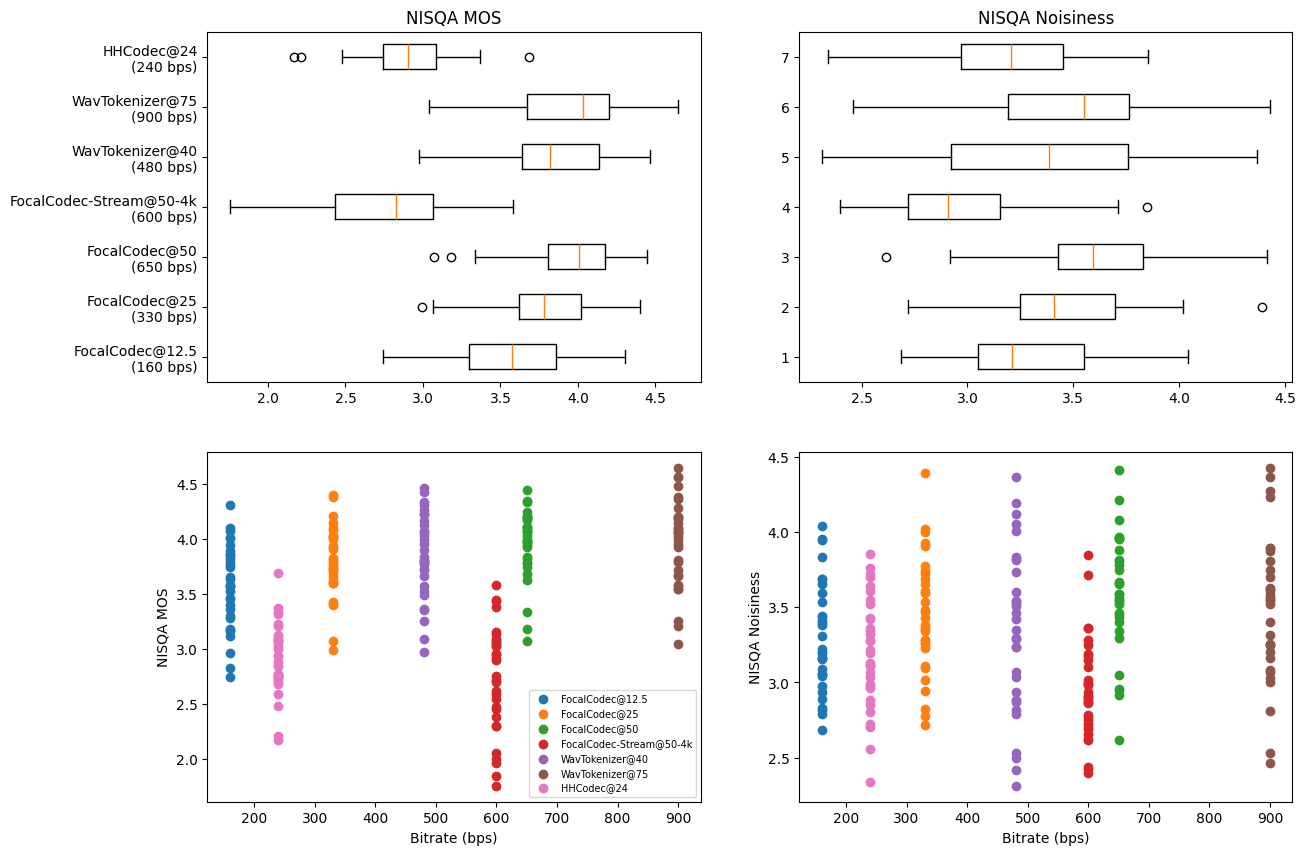

In [54]:
fig, ax = plt.subplots(2,2, figsize=(14, 10))
ax[0,0].boxplot(nisqa_mos.values(), labels=labels, orientation="horizontal")
ax[0,0].set_title("NISQA MOS")
ax[0,1].boxplot(nisqa_noisiness.values(), orientation="horizontal")
ax[0,1].set_title("NISQA Noisiness")
for key, value in bitrates.items():
    ax[1,0].scatter(torch.ones(n_speakers)*value, nisqa_mos[key], label=key)
    ax[1,1].scatter(torch.ones(n_speakers)*value, nisqa_noisiness[key], label=key)
ax[1,0].set_xlabel("Bitrate (bps)")
ax[1,0].set_ylabel("NISQA MOS")
ax[1,0].legend(prop={'size': 7})
ax[1,1].set_xlabel("Bitrate (bps)")
ax[1,1].set_ylabel("NISQA Noisiness")
plt.show()

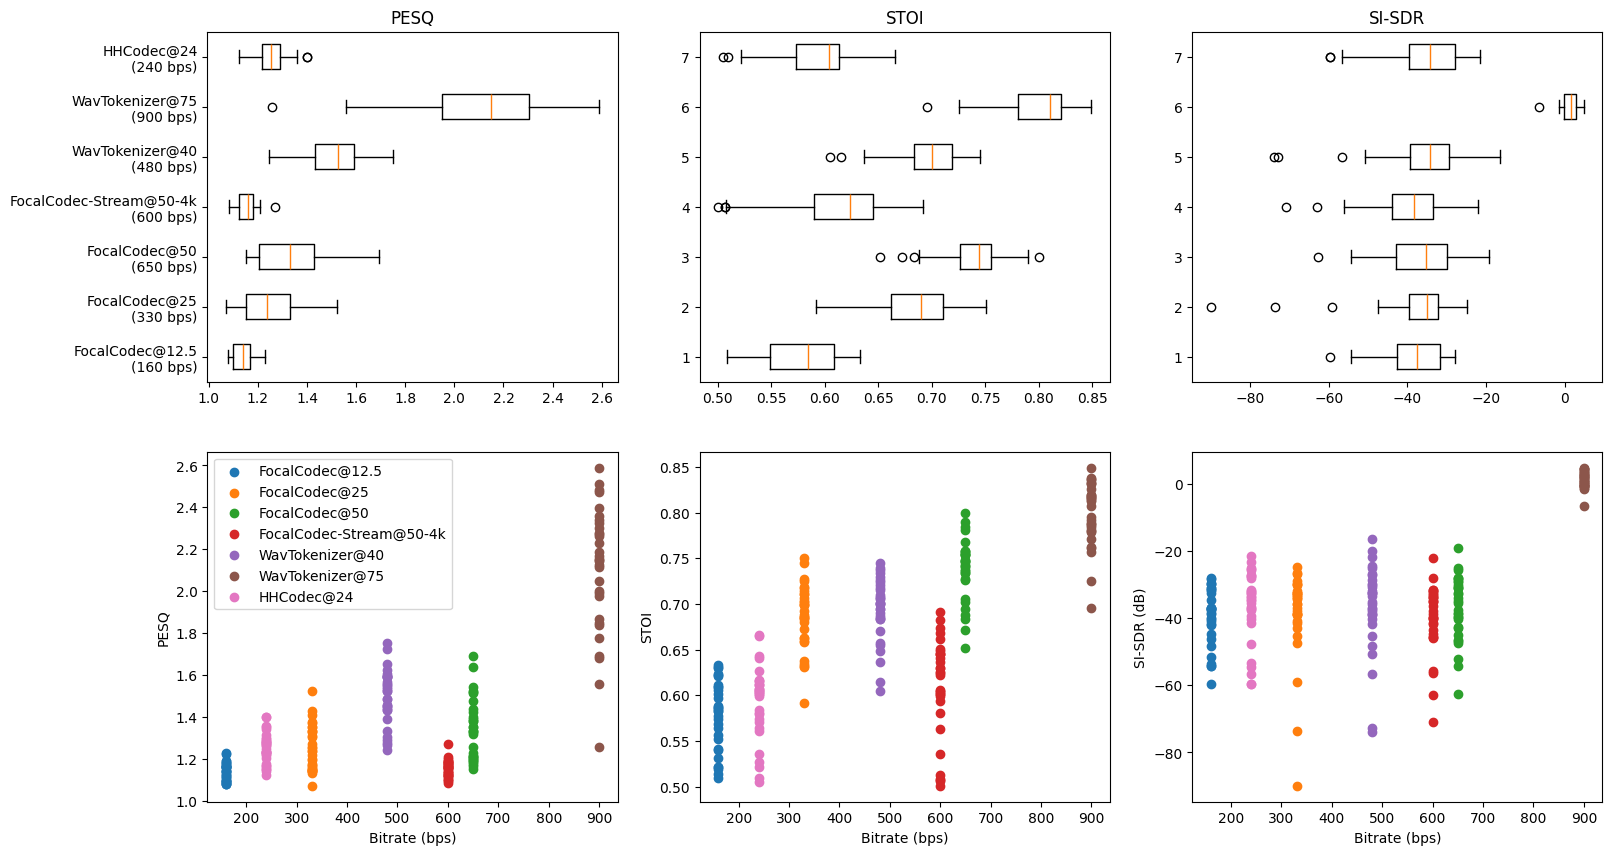

In [55]:
fig, ax = plt.subplots(2,3, figsize=(18, 10))
ax[0,0].boxplot(pesq_.values(), labels=labels, orientation="horizontal")
ax[0,0].set_title("PESQ")
ax[0,1].boxplot(stoi_.values(), orientation="horizontal")
ax[0,1].set_title("STOI")
ax[0,2].boxplot(si_sdr_.values(), orientation="horizontal")
ax[0,2].set_title("SI-SDR")
for key, value in bitrates.items():
    ax[1,0].scatter(torch.ones(n_speakers)*value, pesq_[key], label=key)
    ax[1,1].scatter(torch.ones(n_speakers)*value, stoi_[key], label=key)
    ax[1,2].scatter(torch.ones(n_speakers)*value, si_sdr_[key], label=key)
ax[1,0].set_xlabel("Bitrate (bps)")
ax[1,0].set_ylabel("PESQ")
ax[1,0].legend()
ax[1,1].set_xlabel("Bitrate (bps)")
ax[1,1].set_ylabel("STOI")
ax[1,2].set_xlabel("Bitrate (bps)")
ax[1,2].set_ylabel("SI-SDR (dB)")
plt.show()

In [56]:
data = []
for model, bitrate in bitrates.items():
    df = pd.DataFrame({
        "Model": model + f" ({bitrate} bps)",
        "PESQ": pesq_[model],
        "STOI": stoi_[model],
        "SI-SDR": si_sdr_[model],
        "NISQA_MOS": nisqa_mos[model],
        "NISQA_Noisiness": nisqa_noisiness[model]
    })
    data.append(df)
df = pd.concat(data, ignore_index=True)
order = list(df["Model"].unique())

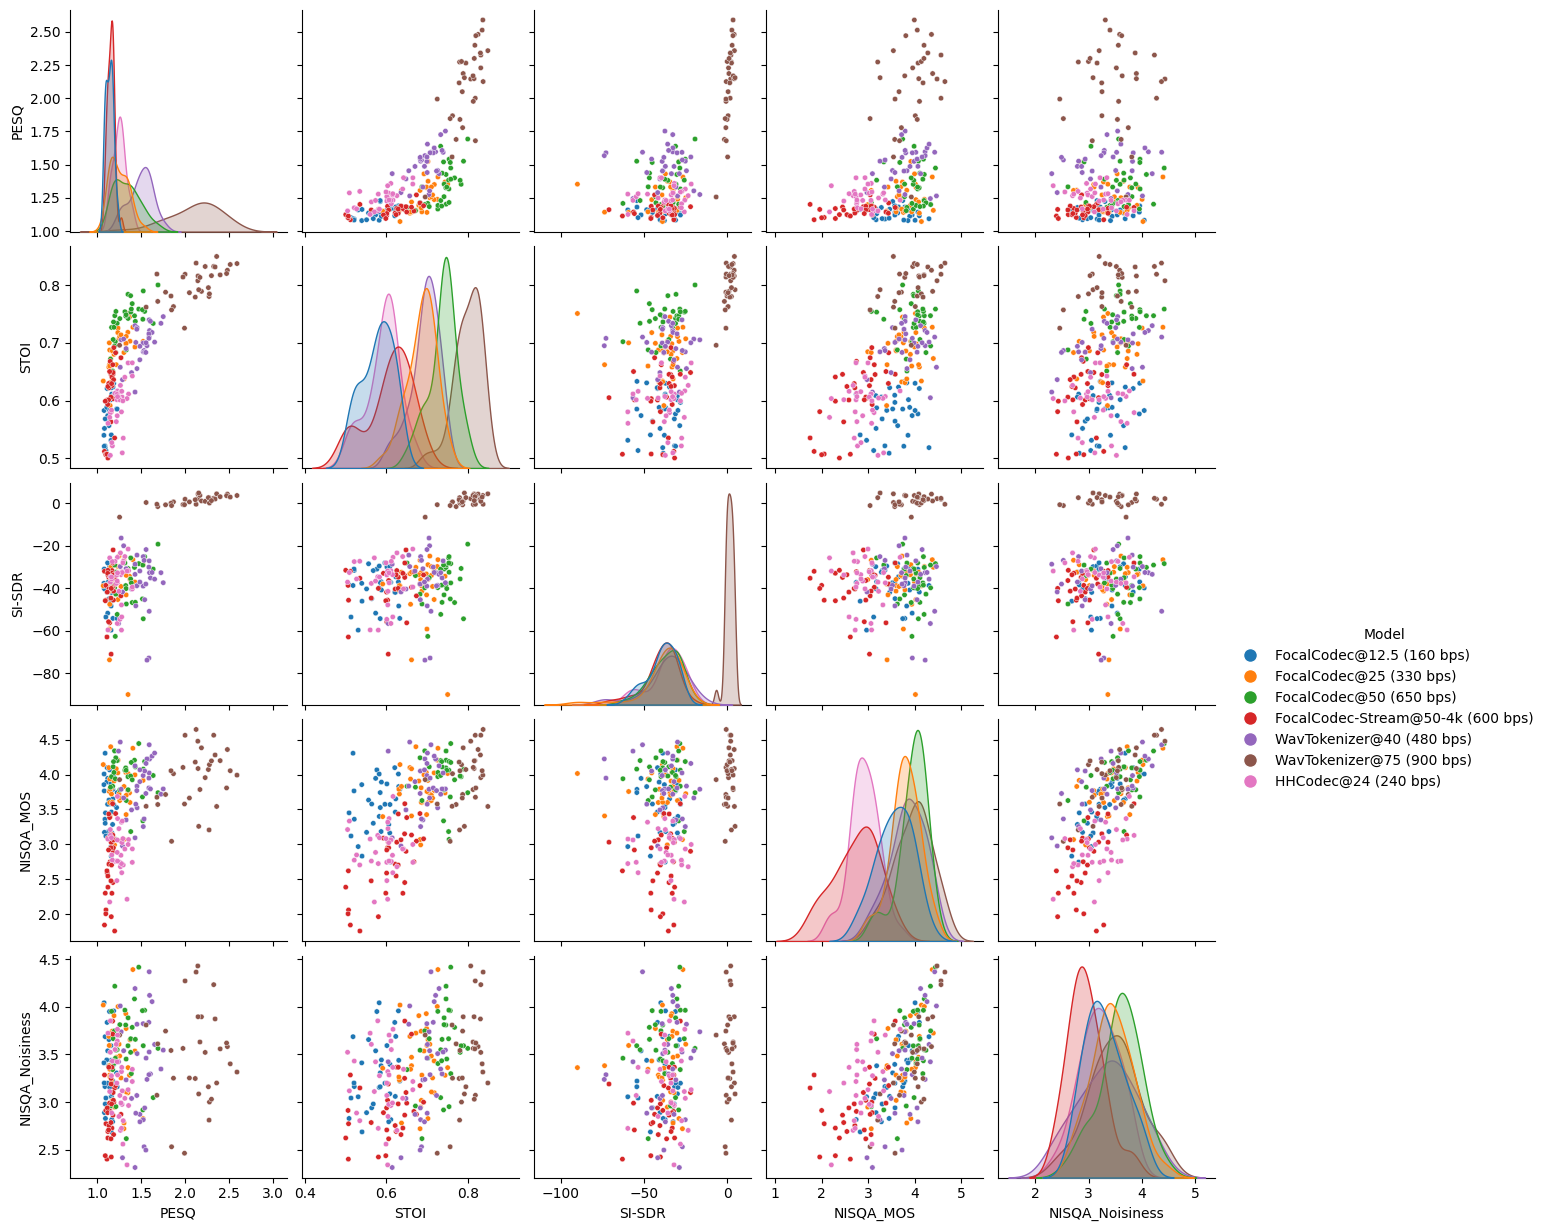

In [57]:
g = sns.pairplot(df, hue="Model", plot_kws={'s': 15})

if g._legend:
    g._legend.remove()

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label=m,
           markerfacecolor=g.palette[i], markersize=10, alpha=1) 
    for i, m in enumerate(order)
]

g.figure.legend(handles=legend_elements, title="Model", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

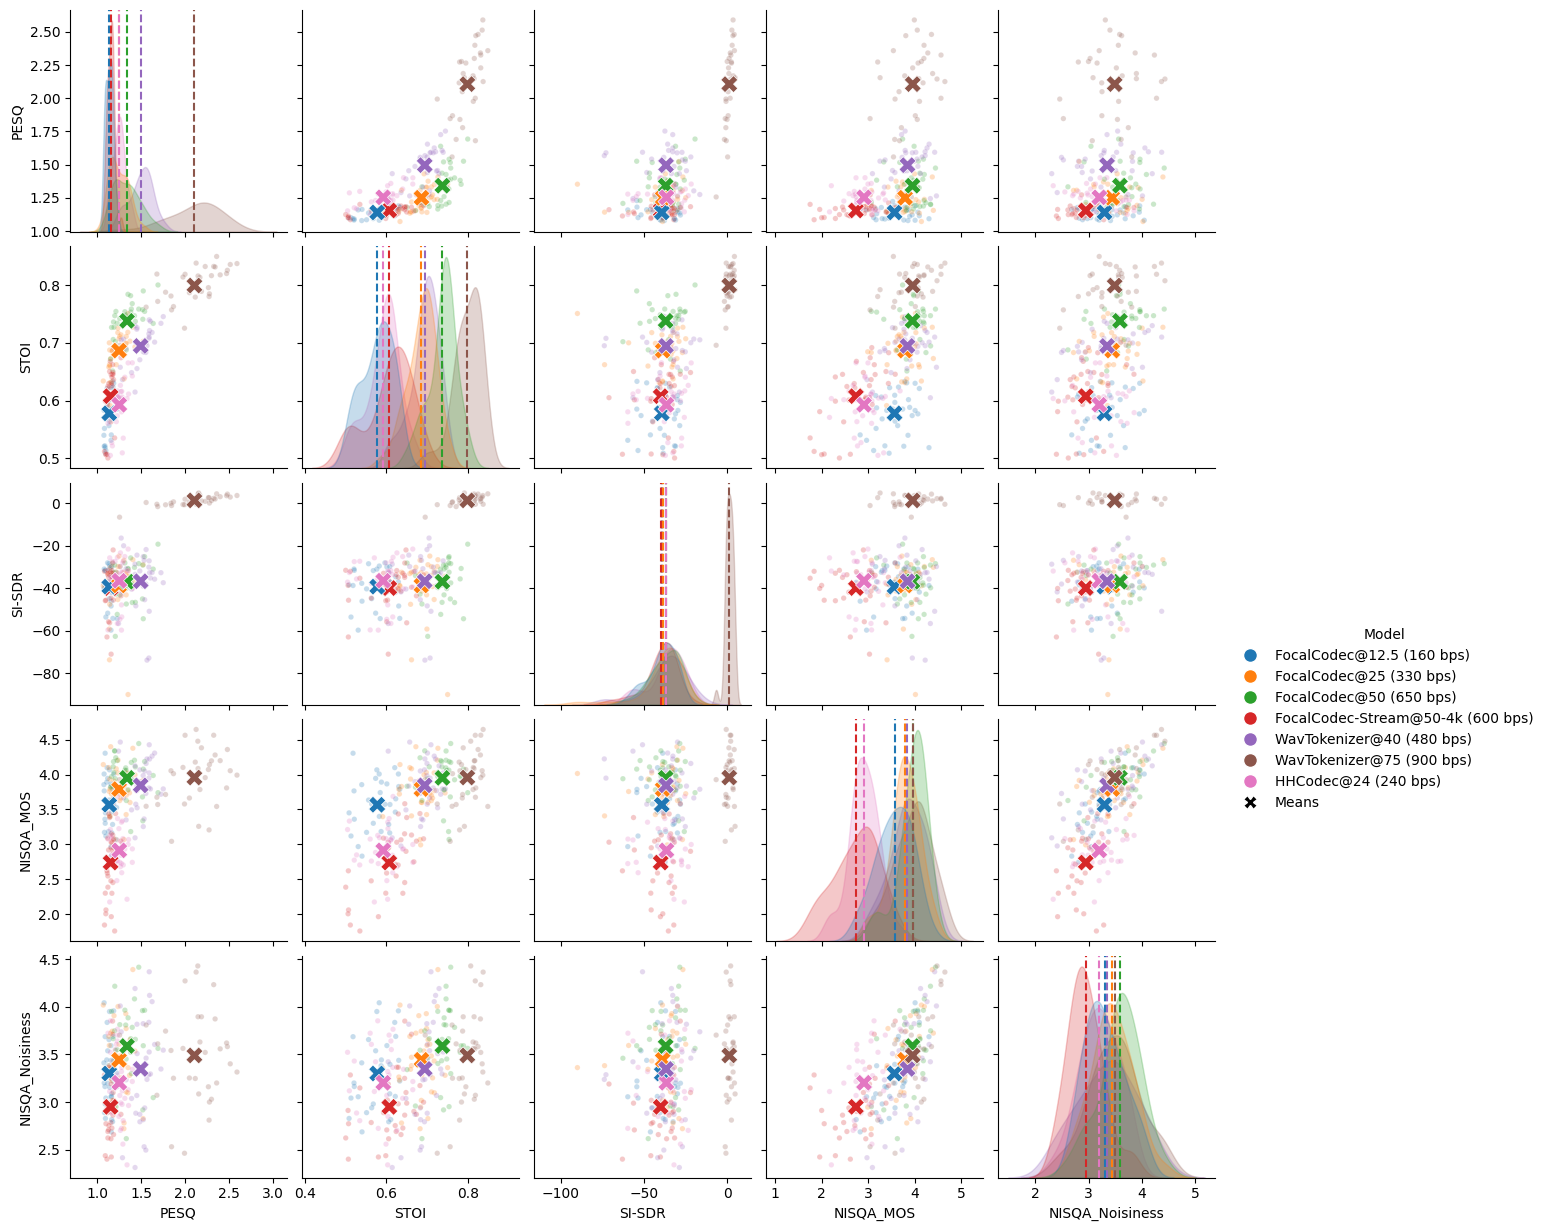

In [58]:
means = df.groupby('Model').mean(numeric_only=True).reset_index()

g_means = sns.pairplot(df, hue="Model", plot_kws={'alpha': 0.25, 's': 15}, diag_kind="kde", hue_order=order)

for ax in g_means.diag_axes:
    for collection in ax.collections:
        collection.set_alpha(0.25)

for i, y_var in enumerate(g_means.y_vars):
    for j, x_var in enumerate(g_means.x_vars):
        ax = g_means.axes[i, j]

        if i != j:
            sns.scatterplot(data=means, x=x_var, y=y_var, hue='Model', hue_order=order, marker='X', s=150,linewidth=0.5, ax=ax, legend=False)
        
        else:
            for idx, model_name in enumerate(order):
                val = means.loc[means['Model'] == model_name, x_var].values[0]
                ax.axvline(val, color=g.palette[idx], linestyle="--")

            ax.set_zorder(1) 
            ax.patch.set_visible(False)

if g_means._legend:
    g_means._legend.remove()

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label=m,
           markerfacecolor=g_means.palette[i], markersize=10, alpha=1) 
    for i, m in enumerate(order)
]

legend_elements.append(Line2D([0], [0], marker='X', color='w', label='Means',
                              markerfacecolor='black', markersize=10))

g_means.figure.legend(handles=legend_elements, title="Model", bbox_to_anchor=(1, 0.5), frameon=False)

plt.show()

In [59]:
means

,Model,PESQ,STOI,SI-SDR,NISQA_MOS,NISQA_Noisiness
0,FocalCodec-Stream@50-4k (600 bps),1.154029,0.607789,-39.909672,2.737116,2.948997
1,FocalCodec@12.5 (160 bps),1.139056,0.578117,-39.245516,3.566177,3.299512
2,FocalCodec@25 (330 bps),1.250022,0.686664,-38.679617,3.791845,3.443558
3,FocalCodec@50 (650 bps),1.340797,0.738077,-36.907275,3.952312,3.588100
4,HHCodec@24 (240 bps),1.252840,0.592926,-36.455767,2.911309,3.202064
5,WavTokenizer@40 (480 bps),1.495501,0.694664,-36.685908,3.844349,3.347336
6,WavTokenizer@75 (900 bps),2.106043,0.799156,1.318197,3.957018,3.489300


In [60]:
df[df["Model"] == "WavTokenizer@75 (900 bps)"]

,Model,PESQ,STOI,SI-SDR,NISQA_MOS,NISQA_Noisiness
160,WavTokenizer@75 (900 bps),1.999701,0.818625,1.865135,4.563262,4.272309
161,WavTokenizer@75 (900 bps),2.144465,0.807446,2.152573,4.478103,4.429621
162,WavTokenizer@75 (900 bps),2.358290,0.849418,4.412430,3.541704,3.199741
163,WavTokenizer@75 (900 bps),1.689277,0.771688,-1.596573,3.570009,3.611030
164,WavTokenizer@75 (900 bps),1.557474,0.761753,0.325832,3.544160,3.808897
165,WavTokenizer@75 (900 bps),1.255840,0.695804,-6.573385,3.926805,3.702912
166,WavTokenizer@75 (900 bps),2.185846,0.789036,1.081938,4.383621,3.895593
167,WavTokenizer@75 (900 bps),2.125331,0.837937,-0.511761,4.646860,4.365149
168,WavTokenizer@75 (900 bps),2.324953,0.832176,2.285955,4.563914,4.233149
169,WavTokenizer@75 (900 bps),1.778148,0.787579,-0.744732,3.713628,3.744925
